In [1]:
import warnings; warnings.filterwarnings('ignore')
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('C:\\Users\\saurabh\\Downloads\\hotel_bookings.csv')
print(df.shape)       # (119390, 36) aana chahiye
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,no,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
1,Resort Hotel,no,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,7/1/2015
2,Resort Hotel,no,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
3,Resort Hotel,no,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,7/2/2015
4,Resort Hotel,no,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,7/3/2015


In [2]:
df.info()
print(df.isnull().sum()[df.isnull().sum() > 0])
df.describe().T
df['is_canceled'].value_counts(normalize=True)

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  str    
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

is_canceled
no     0.629584
yes    0.370416
Name: proportion, dtype: float64

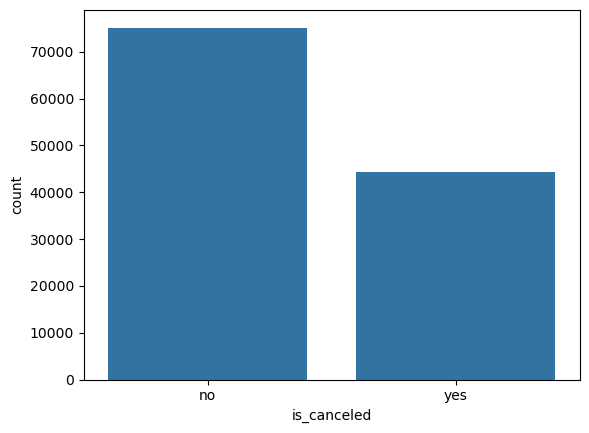

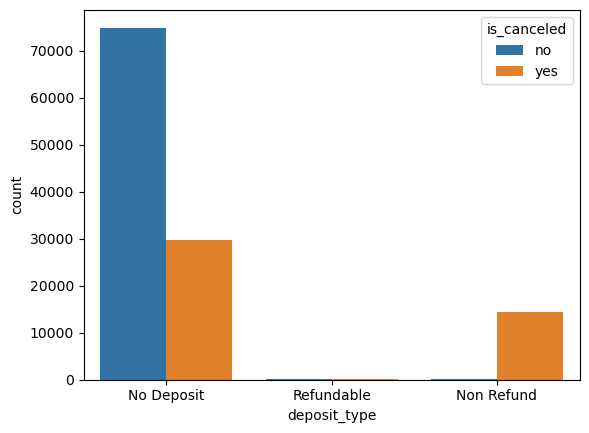

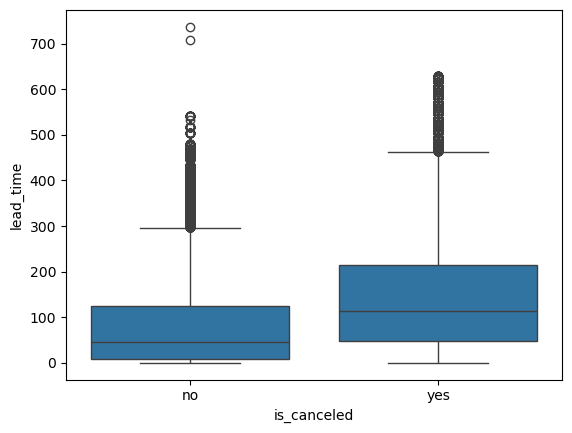

In [3]:
sns.countplot(x='is_canceled', data=df); plt.show()
sns.countplot(x='deposit_type', hue='is_canceled', data=df); plt.show()
sns.boxplot(x='is_canceled', y='lead_time', data=df); plt.show()

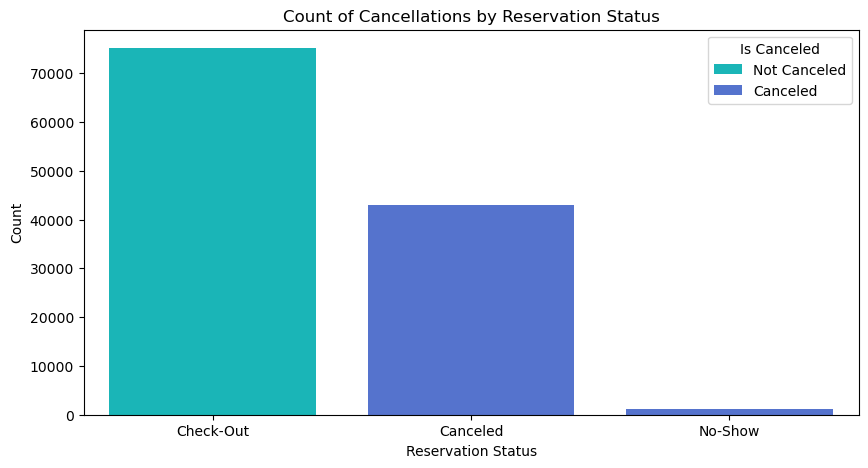

In [4]:
# Bivariate bar plot of 'is_canceled' vs 'reservation_status' with specified colors
plt.figure(figsize=(10, 5))
sns.countplot(x='reservation_status', hue='is_canceled', data=df, palette=['darkturquoise', 'royalblue'])
plt.title('Count of Cancellations by Reservation Status')
plt.xlabel('Reservation Status')
plt.ylabel('Count')
plt.legend(title='Is Canceled', labels=['Not Canceled', 'Canceled'])
plt.show()

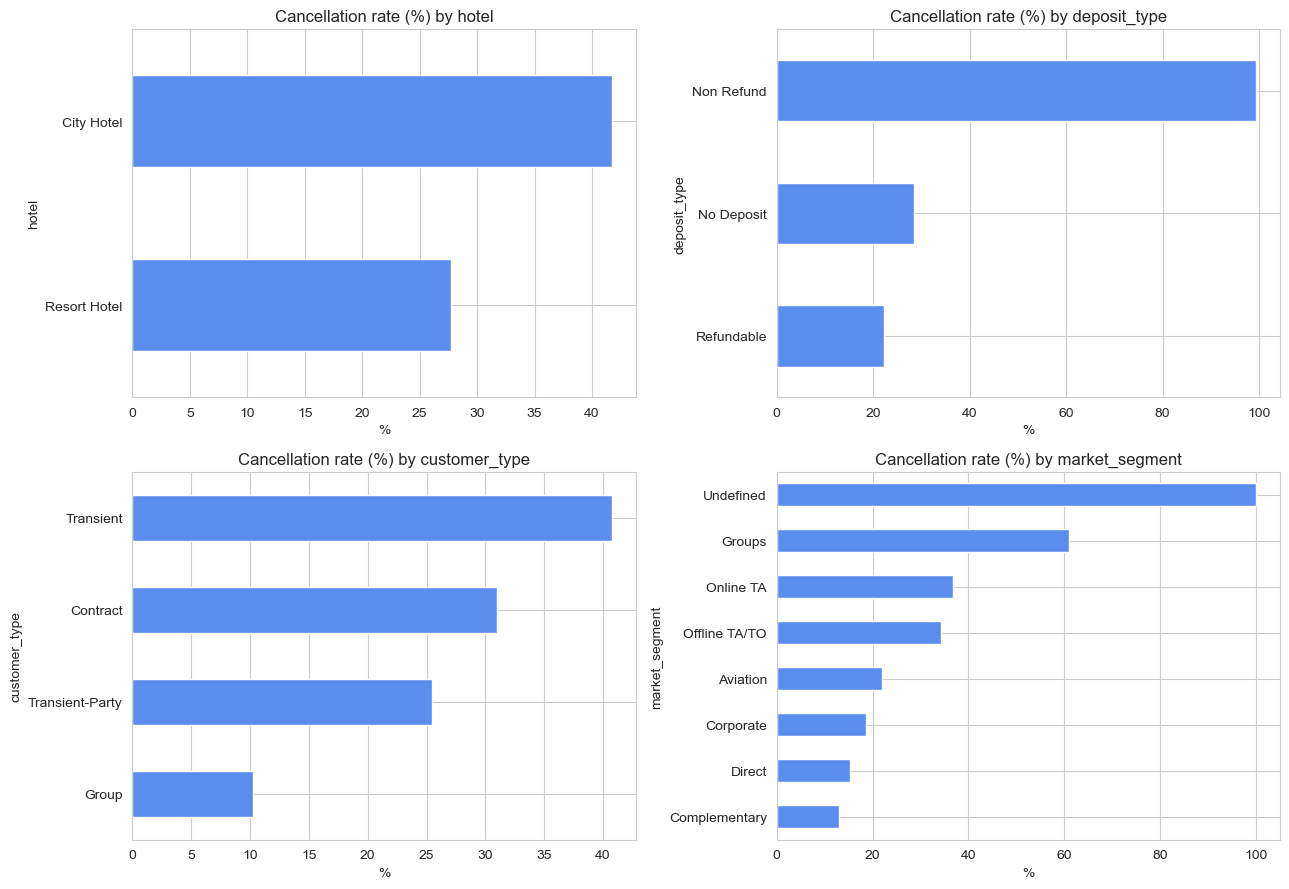

In [5]:
sns.set_style("whitegrid")



# target 'yes'/'no' ko 1/0 banao
df["is_canceled"] = (df["is_canceled"].astype(str).str.strip().str.lower()
                     .map({"yes": 1, "no": 0, "1": 1, "0": 0}))

# 2x2 grid: 4 columns ka cancellation rate (%)
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
for a, col in zip(ax.ravel(), ["hotel", "deposit_type", "customer_type", "market_segment"]):
    (df.groupby(col)["is_canceled"].mean() * 100).sort_values().plot.barh(ax=a, color="#5b8def")
    a.set_title(f"Cancellation rate (%) by {col}")
    a.set_xlabel("%")

plt.tight_layout()
plt.savefig("02_cancel_rate_by_category.png", dpi=110)   # file save karne ke liye
plt.show()

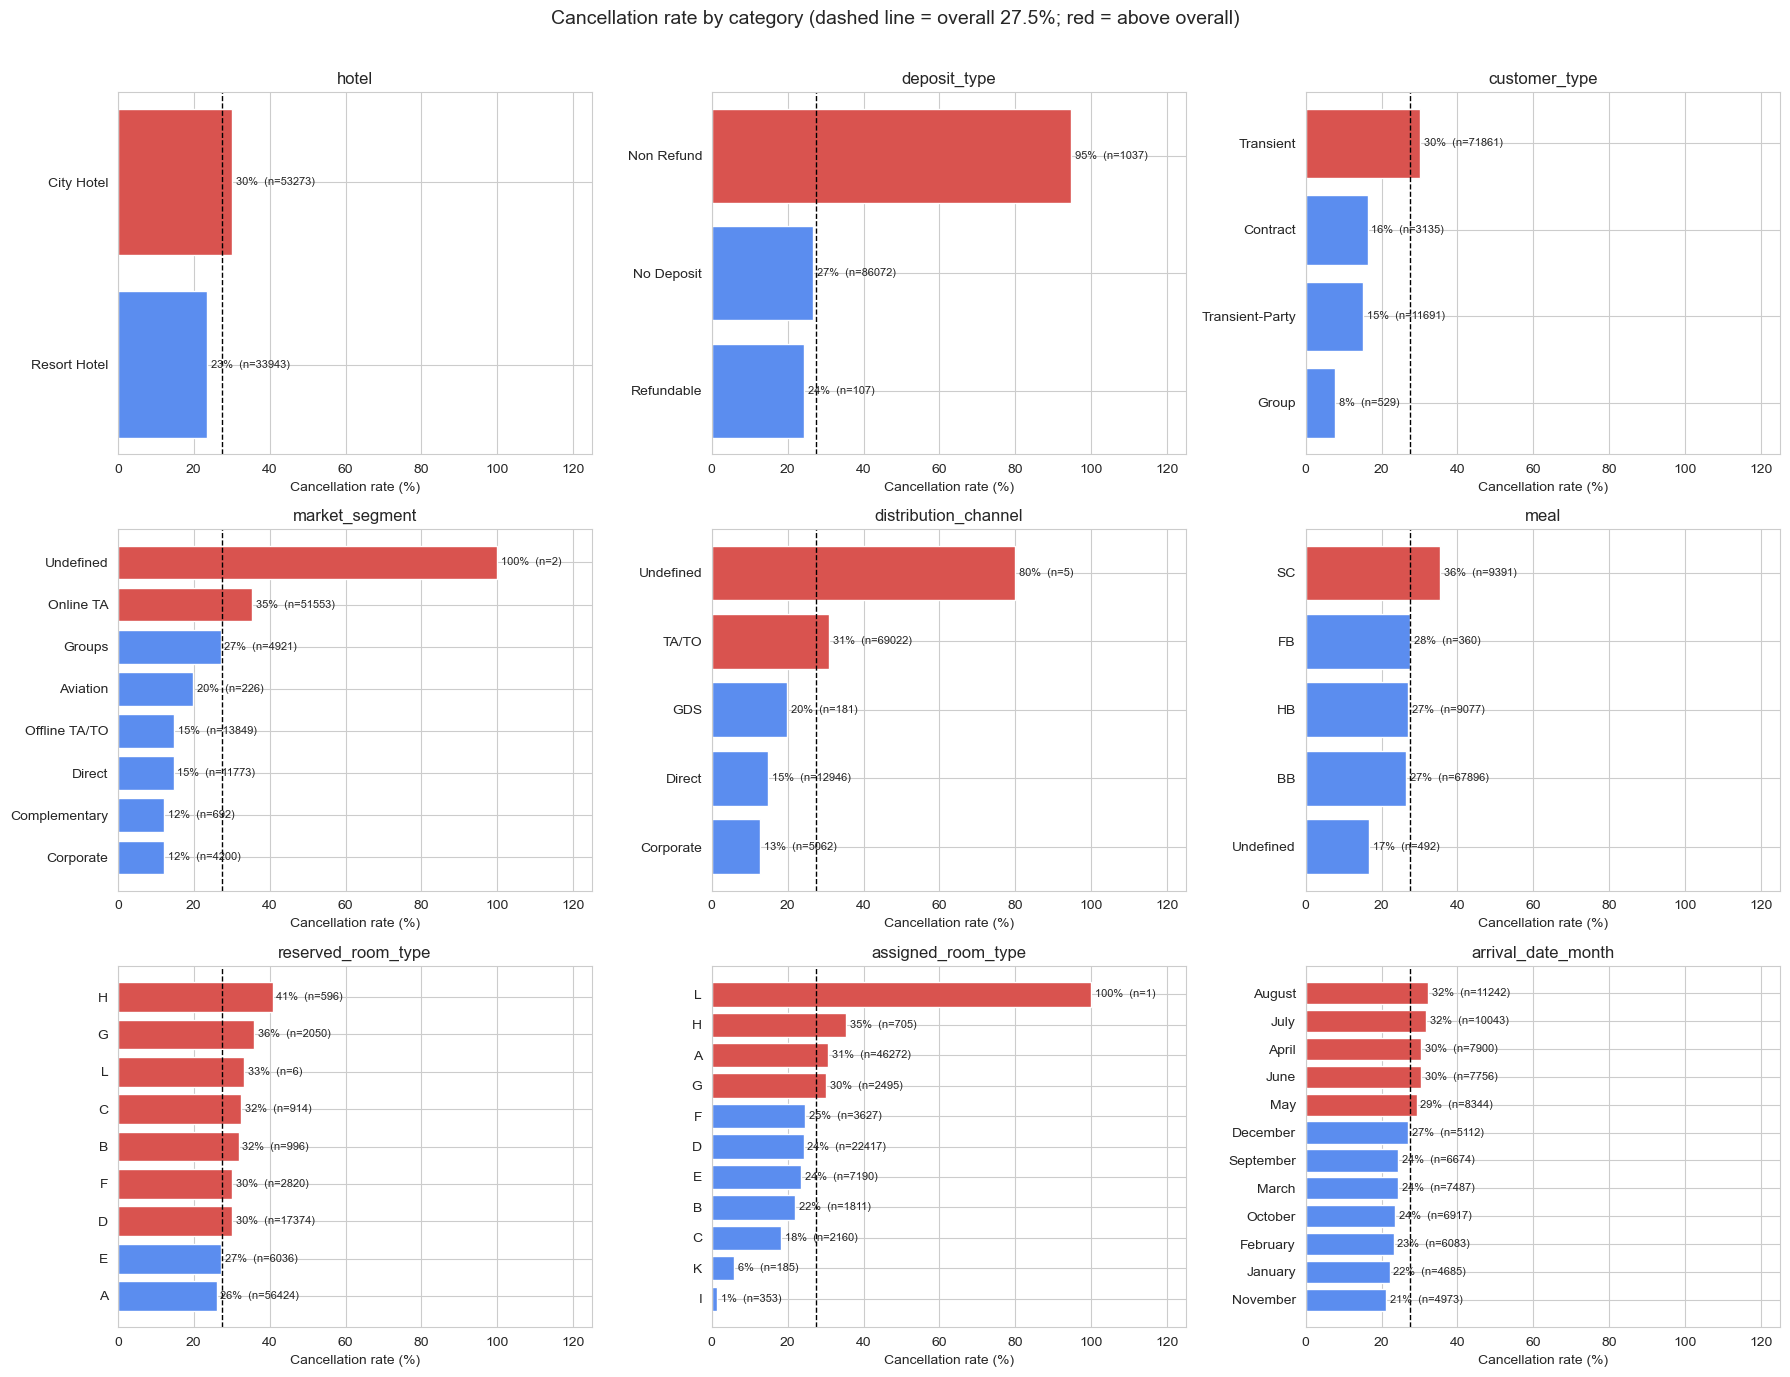

In [6]:
df["children"] = df["children"].fillna(0)
df = df.drop_duplicates()
df = df[(df["adults"] + df["children"] + df["babies"]) > 0]
df = df[(df["adr"] >= 0) & (df["adr"] < 1000) & (df["adults"] <= 10)]

overall = df["is_canceled"].mean() * 100          # dashed line ke liye (27.8%)

# ---------- 3. Plot ----------
cat_cols = ["hotel", "deposit_type", "customer_type",
            "market_segment", "distribution_channel", "meal",
            "reserved_room_type", "assigned_room_type", "arrival_date_month"]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, c in zip(axes.ravel(), cat_cols):
    g = df.groupby(c)["is_canceled"].agg(["mean", "count"]).sort_values("mean")

    # overall se upar = laal, neeche = neela
    colors = ["#d9534f" if m * 100 > overall else "#5b8def" for m in g["mean"]]

    ax.barh(g.index.astype(str), g["mean"] * 100, color=colors)
    ax.axvline(overall, color="black", ls="--", lw=1)       # overall rate ki line

    # har bar ke saath "rate% (n=count)" likho
    for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(m * 100 + 1, i, f"{m*100:.0f}%  (n={n})", va="center", fontsize=8)

    ax.set_xlim(0, 125)
    ax.set_title(c)
    ax.set_xlabel("Cancellation rate (%)")

fig.suptitle(f"Cancellation rate by category (dashed line = overall {overall:.1f}%; red = above overall)",
             fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("05_cancel_rate_all_categories.png", dpi=100)   # image save
plt.show()

In [7]:
# 1) Leakage wale columns
df = df.drop(columns=['reservation_status', 'reservation_status_date', 'assigned_room_type'],
             errors='ignore')

# 2) number_of_bookings sirf tab banao jab 'name' column ho
if 'name' in df.columns:
    df['number_of_bookings'] = df.groupby('name')['name'].transform('count')

# 3) Irrelevant / high cardinality (jo columns nahi hain unhe ignore karega)
df = df.drop(columns=['arrival_date_year', 'name', 'country', 'agent', 'company',
                      'email', 'phone-number', 'credit_card'], errors='ignore')

# 4) Missing values + noise
df['children'] = df['children'].fillna(0)
df.loc[df['adr'] < 0, 'adr'] = df['adr'].median()
df = df[(df['adults'] != 0) & (df['children'] != 10) & (df['babies'] != 10)].reset_index(drop=True)

print(df.shape)
print(df.columns.tolist())

(86995, 25)
['hotel', 'is_canceled', 'lead_time', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'booking_changes', 'deposit_type', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']


In [8]:
months = ['January','February','March','April','May','June','July',
          'August','September','October','November','December']
df['arrival_date_month'] = df['arrival_date_month'].apply(lambda x: months.index(x) + 1)

one_hot_cols = ['hotel','meal','market_segment','distribution_channel',
                'reserved_room_type','deposit_type','customer_type']
df = pd.get_dummies(df, columns=one_hot_cols, drop_first=True, dtype=int)
print(df.shape)

(86995, 47)


In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('C:\\Users\\saurabh\\Downloads\\hotel_bookings.csv')
df['is_canceled'] = pd.to_numeric(df['is_canceled'], errors='coerce')
df = df.dropna(subset=['is_canceled'])
df['is_canceled'] = df['is_canceled'].astype(int)

# Feature selection + cleaning
df = df.drop(columns=['reservation_status', 'reservation_status_date', 'assigned_room_type',
                      'arrival_date_year', 'country', 'agent', 'company',
                      'name', 'email', 'phone-number', 'credit_card'], errors='ignore')
df['children'] = df['children'].fillna(0)
df.loc[df['adr'] < 0, 'adr'] = df['adr'].median()
df = df[(df['adults'] != 0) & (df['children'] != 10) & (df['babies'] != 10)].reset_index(drop=True)

# Encoding
months = ['January','February','March','April','May','June','July',
          'August','September','October','November','December']
df['arrival_date_month'] = df['arrival_date_month'].apply(lambda x: months.index(x) + 1)
one_hot_cols = ['hotel','meal','market_segment','distribution_channel',
                'reserved_room_type','deposit_type','customer_type']
df = pd.get_dummies(df, columns=one_hot_cols, drop_first=True, dtype=int)

# Sample
df, _ = train_test_split(df, train_size=25000, stratify=df['is_canceled'], random_state=42)
df = df.reset_index(drop=True)

print(df.shape)
print(df['is_canceled'].mean())
print(df.dtypes.value_counts())

ValueError: train_size=25000 should be either positive and smaller than the number of samples 0 or a float in the (0, 1) range

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('C:\\Users\\saurabh\\Downloads\\hotel_bookings.csv')

# is_canceled ko 0/1 mein badlo (text ho ya number, dono chalega)
s = df['is_canceled'].astype(str).str.strip().str.lower()
mapping = {'0': 0, '1': 1, '0.0': 0, '1.0': 1,
           'no': 0, 'yes': 1, 'false': 0, 'true': 1,
           'not canceled': 0, 'canceled': 1, 'cancelled': 1,
           'not cancelled': 0, 'check-out': 0, 'no-show': 1}
df['is_canceled'] = s.map(mapping)
print("Unmapped rows:", df['is_canceled'].isna().sum())   # 0 aana chahiye

df = df.dropna(subset=['is_canceled']).copy()
df['is_canceled'] = df['is_canceled'].astype(int)
print("After target fix:", df.shape)

# Feature selection + cleaning
df = df.drop(columns=['reservation_status', 'reservation_status_date', 'assigned_room_type',
                      'arrival_date_year', 'country', 'agent', 'company',
                      'name', 'email', 'phone-number', 'credit_card'], errors='ignore')

for c in ['children', 'adults', 'babies', 'adr']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df['children'] = df['children'].fillna(0)
df.loc[df['adr'] < 0, 'adr'] = df['adr'].median()
print("Before noise filter:", df.shape)

df = df[(df['adults'] != 0) & (df['children'] != 10) & (df['babies'] != 10)].reset_index(drop=True)
print("After noise filter:", df.shape)

# Encoding
months = ['January','February','March','April','May','June','July',
          'August','September','October','November','December']
df['arrival_date_month'] = df['arrival_date_month'].astype(str).str.strip().str.capitalize().apply(
    lambda x: months.index(x) + 1)
one_hot_cols = ['hotel','meal','market_segment','distribution_channel',
                'reserved_room_type','deposit_type','customer_type']
df = pd.get_dummies(df, columns=one_hot_cols, drop_first=True, dtype=int)

# Sample
df, _ = train_test_split(df, train_size=25000, stratify=df['is_canceled'], random_state=42)
df = df.reset_index(drop=True)

print(df.shape, df['is_canceled'].mean())
print(df.dtypes.value_counts())

Unmapped rows: 0
After target fix: (119390, 32)
Before noise filter: (119390, 25)
After noise filter: (118985, 25)
(25000, 47) 0.37076
int64      45
float64     2
Name: count, dtype: int64


In [11]:
import os
from sklearn.model_selection import train_test_split

X = df.drop('is_canceled', axis=1)
y = df['is_canceled']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

os.makedirs('model', exist_ok=True)

test_df = X_test.copy()
test_df['is_canceled'] = y_test
test_df.to_csv('test_data.csv', index=False)

print(X_train.shape, X_test.shape)

(20000, 46) (5000, 46)


In [12]:
import joblib
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef)

models = {
    'Logistic Regression': Pipeline([('scaler', StandardScaler()),
                                     ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    'KNN': Pipeline([('scaler', StandardScaler()),
                     ('clf', KNeighborsClassifier(n_neighbors=5))]),
    'Naive Bayes': GaussianNB(),
    'SVM': Pipeline([('scaler', StandardScaler()),
                     ('clf', SVC(kernel='rbf', probability=True, random_state=42))]),
}

results = []
for name, model in models.items():
    print(f'Training {name}...')
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'ML Model Name': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'MCC': matthews_corrcoef(y_test, y_pred),
    })

    joblib.dump(model, f"model/{name.lower().replace(' ', '_')}.joblib")

results_df = pd.DataFrame(results).round(4)
results_df.to_csv('model/metrics_comparison.csv', index=False)
results_df

Training Logistic Regression...
Training Decision Tree...
Training KNN...
Training Naive Bayes...
Training SVM...


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8046,0.8459,0.8227,0.6030,0.6959,0.5715
1,Decision Tree,0.8082,0.8643,0.7908,0.6564,0.7174,0.5798
2,KNN,0.7874,0.8337,0.7381,0.6613,0.6976,0.5363
3,Naive Bayes,0.5574,0.7819,0.4516,0.9024,0.6019,0.2828
4,SVM,0.8066,0.8576,0.8332,0.5982,0.6964,0.5766


In [13]:
import sklearn
with open('requirements.txt', 'w') as f:
    f.write(f"streamlit\nscikit-learn=={sklearn.__version__}\nnumpy\npandas\nmatplotlib\nseaborn\njoblib\n")
print(open('requirements.txt').read())

streamlit
scikit-learn==1.6.1
numpy
pandas
matplotlib
seaborn
joblib



In [14]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report)

TARGET = 'is_canceled'
MODEL_FILES = {
    'Logistic Regression': 'model/logistic_regression.joblib',
    'Decision Tree': 'model/decision_tree.joblib',
    'KNN': 'model/knn.joblib',
    'Naive Bayes': 'model/naive_bayes.joblib',
    'SVM': 'model/svm.joblib',
}

st.set_page_config(page_title="Hotel Booking Cancellation", layout="wide")
st.title("Hotel Booking Cancellation Prediction")
st.write("Upload the **test CSV** (features + `is_canceled` column), pick a model, and view the metrics.")


@st.cache_resource
def load_model(path):
    return joblib.load(path)


def get_metrics(model, X, y):
    y_pred = model.predict(X)
    try:
        auc = roc_auc_score(y, model.predict_proba(X)[:, 1])
    except Exception:
        auc = float('nan')
    return {
        'Accuracy': accuracy_score(y, y_pred),
        'AUC': auc,
        'Precision': precision_score(y, y_pred, zero_division=0),
        'Recall': recall_score(y, y_pred, zero_division=0),
        'F1': f1_score(y, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y, y_pred),
    }, y_pred


uploaded = st.file_uploader("Upload test data (CSV)", type=["csv"])

if uploaded is None:
    st.info("Please upload test_data.csv to continue.")
    st.stop()

df = pd.read_csv(uploaded)
st.subheader("Data preview")
st.write(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
st.dataframe(df.head())

if TARGET not in df.columns:
    st.error(f"The CSV must contain the target column '{TARGET}'.")
    st.stop()

y = df[TARGET].astype(int)

model_name = st.selectbox("Select a model", list(MODEL_FILES.keys()))
model = load_model(MODEL_FILES[model_name])

feature_cols = list(model.feature_names_in_)
missing = [c for c in feature_cols if c not in df.columns]
if missing:
    st.error(f"Missing required feature columns: {missing}")
    st.stop()
X = df[feature_cols]

metrics, y_pred = get_metrics(model, X, y)

st.subheader(f"Evaluation metrics: {model_name}")
cols = st.columns(6)
for col, (k, v) in zip(cols, metrics.items()):
    col.metric(k, f"{v:.4f}")

left, right = st.columns(2)
with left:
    st.subheader("Confusion matrix")
    cm = confusion_matrix(y, y_pred)
    fig, ax = plt.subplots(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not Canceled', 'Canceled'],
                yticklabels=['Not Canceled', 'Canceled'])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    st.pyplot(fig)
with right:
    st.subheader("Classification report")
    report = classification_report(y, y_pred, output_dict=True, zero_division=0)
    st.dataframe(pd.DataFrame(report).T.round(4))

st.subheader("Comparison of all models on this data")
rows = []
for name, path in MODEL_FILES.items():
    m = load_model(path)
    mt, _ = get_metrics(m, df[list(m.feature_names_in_)], y)
    rows.append({'ML Model Name': name, **mt})
st.dataframe(pd.DataFrame(rows).round(4), use_container_width=True)

Writing app.py


In [15]:
import os
print(os.path.exists('app.py'))
print(sorted(os.listdir('.')))

True
['.Neo4jDesktop2', '.anaconda', '.aws', '.bash_history', '.conda', '.condarc', '.continuum', '.copilot', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.keras', '.matplotlib', '.python_history', '.ssh', '.streamlit', '.th-client', '.virtual_documents', '.vscode', '.vscode-shared', '02_cancel_rate_by_category.png', '05_cancel_rate_all_categories.png', '17-04-2024 630AM.ipynb', '2026AK05716.ipynb', '2026AK05716__Assignment2.ipynb', '27_4_2026_Lang_Translator_genai_first.ipynb', '2_Survey.ipynb', '3D Objects', 'AppData', 'Application Data', 'Audio_CLassification_TimeSeriesAnalysis.ipynb', 'Chatbot (1) (1).ipynb', 'Chatbot_usingOpenAI.ipynb', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'GenAI_Project_CHATGPT_SAS.ipynb', 'GraphDB with neo4j30jan_31jan_update.ipynb', 'HOTEL_BOOKING.ipynb', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'MicrosoftEdgeBackups', 'Music', 'My Documents', 'NTUSER.DAT', 'NTUSER.DAT{340956d6-e719-11ef-a8cb-34e6d7822

In [16]:
import os
print(os.path.exists('README.md'))
print(sorted(os.listdir('model')))

False
['.ipynb_checkpoints', 'decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'metrics_comparison.csv', 'naive_bayes.joblib', 'svm.joblib']


In [17]:
import os
print(os.path.exists('README.md'))

False


In [18]:
%%writefile README.md
# Hotel Booking Cancellation Prediction

## a. Problem Statement
Predict whether a hotel booking will be canceled (`is_canceled` = 1) or not (0) using booking details such as lead time, deposit type, market segment and special requests. Five classification models are implemented and compared on the same dataset using Accuracy, AUC, Precision, Recall, F1 and MCC. The trained models are deployed in a Streamlit app.

## b. Dataset Description
- Source: Kaggle, Hotel Booking dataset [PASTE KAGGLE LINK HERE]
- Type: binary classification, target = `is_canceled`
- Original size: [ROWS] rows x [COLUMNS] columns. After cleaning and encoding, a stratified sample of 25,000 rows with [NUMBER] input features was used (80/20 train-test split, stratified).
- Preprocessing: removed leakage columns (`reservation_status`, `reservation_status_date`, `assigned_room_type`), dropped irrelevant / high-cardinality columns (`arrival_date_year`, `country`, `agent`, `company`), filled missing `children` with 0, replaced negative `adr` with the median, removed rows with 0 adults and outlier rows (10 children / 10 babies), label-encoded the month, and one-hot encoded the remaining categorical columns.

## c. GitHub Repository Link
[PASTE GITHUB REPO LINK HERE]

Live app: [PASTE STREAMLIT APP LINK HERE]

## d. Models Used

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.8046 | 0.8459 | 0.8227 | 0.6030 | 0.6959 | 0.5715 |
| Decision Tree | 0.8082 | 0.8643 | 0.7908 | 0.6564 | 0.7174 | 0.5798 |
| KNN | 0.7874 | 0.8337 | 0.7381 | 0.6613 | 0.6976 | 0.5363 |
| Naive Bayes | 0.5574 | 0.7819 | 0.4516 | 0.9024 | 0.6019 | 0.2828 |
| Support Vector Machine | 0.8066 | 0.8576 | 0.8332 | 0.5982 | 0.6964 | 0.5766 |

### Observations on model performance

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Good precision (0.82) but low recall (0.60); it misses many real cancellations. A solid, simple baseline. |
| Decision Tree | Best overall: highest AUC, F1 and MCC, with a good balance of precision and recall. |
| KNN | Slightly weaker than the others; sensitive to feature scaling and to the many one-hot columns. |
| Naive Bayes | Very high recall (0.90) but very low precision and accuracy; the Gaussian and independence assumptions do not fit one-hot and skewed features. |
| Support Vector Machine | Highest precision (0.83) and second-best AUC, but recall is low (0.60), so it is conservative about predicting cancellations. |
| **Overall, Winner for your dataset?** | **Decision Tree.** It has the highest AUC (0.8643), Accuracy (0.8082), F1 (0.7174) and MCC (0.5798), with the best balance between precision (0.7908) and recall (0.6564). Support Vector Machine is a close second (AUC 0.8576, highest precision 0.8332), while Naive Bayes is the weakest (Accuracy 0.5574, MCC 0.2828). |

Writing README.md


In [19]:
import os
print(os.path.exists('README.md'))
print(sorted(os.listdir('model')))

True
['.ipynb_checkpoints', 'decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'metrics_comparison.csv', 'naive_bayes.joblib', 'svm.joblib']


In [20]:
import os
for f in sorted(os.listdir('model')):
    p = os.path.join('model', f)
    if os.path.isfile(p):
        print(f, round(os.path.getsize(p)/1e6, 2), 'MB')
print('test_data.csv', round(os.path.getsize('test_data.csv')/1e6, 2), 'MB')

decision_tree.joblib 0.03 MB
knn.joblib 7.52 MB
logistic_regression.joblib 0.0 MB
metrics_comparison.csv 0.0 MB
naive_bayes.joblib 0.0 MB
svm.joblib 3.61 MB
test_data.csv 0.52 MB
